# Group 74 – AI-ML Assessment 1
## Exercise 2: Baseline CNN Classifier

This notebook implements a three-trainable-layer Convolutional Neural Network (CNN) for CIFAR-10 image classification and compares its performance with the Exercise 1 MLP baseline.

## 1. Imports and Settings

In [ ]:
import sys, time, random, hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# group settings
SEED        = 42
BATCH_SIZE  = 128
EPOCHS      = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.0
VAL_SIZE    = 5000            # from train set only
NUM_WORKERS = 0
DATA_DIR    = "./data"

# normalisation values
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

CLASS_NAMES = ["aeroplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {device}")

In [ ]:
import platform

def cpu_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if "model name" in line:
                    return line.split(":")[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("CPU:", cpu_name())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

## 2. Random Seed Setup

In [ ]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed set to {SEED}")

## 3. CIFAR-10 Dataset Preparation and Train/Validation Split

In [ ]:
# no augmentation here
base_transform = transforms.Compose([
    transforms.ToTensor(),                              # image to tensor
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),        # normalise
])
train_transform = base_transform   # ex 3 changes this one
eval_transform  = base_transform   # keep val/test fixed

# load data
full_train_for_train = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=train_transform)
full_train_for_val   = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=eval_transform)
test_dataset         = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_transform)

# 45k train / 5k val split
split_generator = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(full_train_for_train), generator=split_generator).numpy()
val_indices   = np.sort(perm[:VAL_SIZE])
train_indices = np.sort(perm[VAL_SIZE:])

train_dataset      = Subset(full_train_for_train, train_indices.tolist())
validation_dataset = Subset(full_train_for_val,   val_indices.tolist())

# same value everywhere = same split
split_hash = hashlib.md5(val_indices.tobytes()).hexdigest()
print(f"Split seed: {SEED} | validation-index fingerprint (md5): {split_hash}")

## 4. DataLoaders

In [20]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                          generator=loader_generator, pin_memory=(device.type == "cuda"))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

## 5. Dataset Sanity Checks

Train / Val / Test sizes: 45000 / 5000 / 10000
Batch shape: (128, 3, 32, 32) | label dtype: torch.int64
Per-channel batch mean (should be near 0): [-0.039 -0.037 -0.034]
Per-channel batch std  (should be near 1): [1.016 1.017 1.003]
All sanity checks passed.


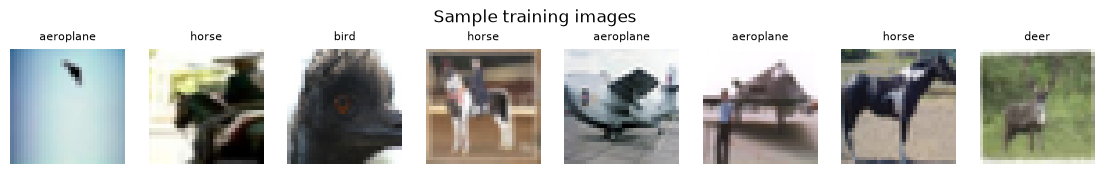

In [21]:
assert len(train_dataset) == 45000,      f"Train size is {len(train_dataset)}"
assert len(validation_dataset) == 5000,  f"Validation size is {len(validation_dataset)}"
assert len(test_dataset) == 10000,       f"Test size is {len(test_dataset)}"
assert len(set(train_indices) & set(val_indices)) == 0, "Train/validation overlap!"
assert len(train_indices) + len(val_indices) == 50000

images, labels = next(iter(train_loader))
assert images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {images.shape}"
assert labels.min() >= 0 and labels.max() <= 9, "Labels outside 0-9"
assert torch.isfinite(images).all(), "Non-finite pixel values"

print(f"Train / Val / Test sizes: {len(train_dataset)} / {len(validation_dataset)} / {len(test_dataset)}")
print(f"Batch shape: {tuple(images.shape)} | label dtype: {labels.dtype}")
print("Per-channel batch mean (should be near 0):", images.mean(dim=(0, 2, 3)).numpy().round(3))
print("Per-channel batch std  (should be near 1):", images.std(dim=(0, 2, 3)).numpy().round(3))
print("All sanity checks passed.")

# look at a few images
mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, images[:8], labels[:8]):
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[lbl], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

 ## 6. Baseline CNN Architecture

Proposed baseline:
- Input: 3 × 32 × 32 RGB image
- Conv2D 1: 3 to 32 channels, 3×3 kernel, padding 1
- ReLU and 2×2 MaxPooling
- Conv2D 2: 32 to 64 channels, 3×3 kernel, padding 1
- ReLU and 2×2 MaxPooling
- Flatten: 4096 features
- Linear: 4096 to 10 output logits

Total trainable layers: 3
Loss function: CrossEntropyLoss

In [22]:

# Exercise 2 - Baseline CNN Model
# Architecture: 2 Conv2D layers + 1 Linear layer

class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Trainable Layer 1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Trainable Layer 2
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # Non trainable operations
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()

        # Trainable Layer 3
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        # First convolution block
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Second convolution block
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Flatten feature maps
        x = self.flatten(x)

        # Classification layer
        x = self.fc(x)

        return x



set_seed(SEED)


model = BaselineCNN().to(device)


print(model)

n_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# Count trainable layers
trainable_layers = sum(
    1 for layer in model.modules()
    if isinstance(layer, (nn.Conv2d, nn.Linear))
)

print("Trainable layers:", trainable_layers)
print("Trainable parameters:", n_params)

# Verify the output dimensions
with torch.no_grad():
    sample_input = torch.randn(4, 3, 32, 32).to(device)
    sample_output = model(sample_input)

print("Output shape:", tuple(sample_output.shape))

assert trainable_layers == 3
assert sample_output.shape == (4, 10)

print("CNN architecture checks passed!")


BaselineCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable layers: 3
Trainable parameters: 60362
Output shape: (4, 10)
CNN architecture checks passed!


## 7. Training and Validation Functions

In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

In [24]:
print("Current model:", type(model).__name__)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

model_params = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_params = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

print("Optimizer connected to CNN:",
      model_params == optimizer_params)

Current model: BaselineCNN
Trainable parameters: 60362
Optimizer connected to CNN: True


## 8. CNN Model Training

In [ ]:


# Confirm that the correct model is selected
assert isinstance(model, BaselineCNN), "CNN model is not selected!"

print("Training model:", type(model).__name__)
print("Epochs:", EPOCHS)
print("Device:", device)


history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}


start = time.time()

for epoch in range(1, EPOCHS + 1):

    tr_loss, tr_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    va_loss, va_acc = evaluate(
        model, validation_loader, criterion, device
    )

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)

    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {tr_loss:.4f} acc {tr_acc:5.2f}% | "
        f"val loss {va_loss:.4f} acc {va_acc:5.2f}%"
    )

training_time = time.time() - start

print(f"\nTotal training time: {training_time:.1f}s on {device}")


Training model: BaselineCNN
Epochs: 20
Device: cpu


NameError: name 's' is not defined

## 9. CNN Loss and Accuracy Plots

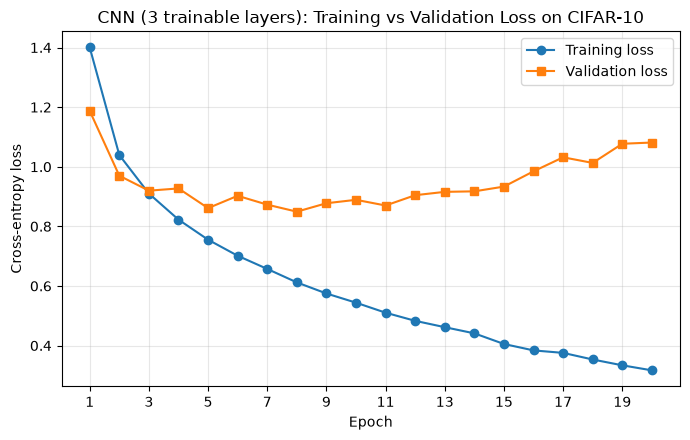

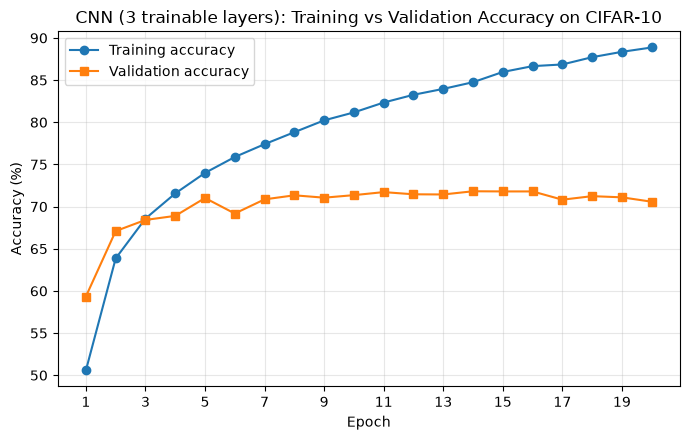

In [ ]:

epochs_range = range(1, EPOCHS + 1)

# CNN loss plot
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history["train_loss"],
         marker="o", label="Training loss")
plt.plot(epochs_range, history["val_loss"],
         marker="s", label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CNN (3 trainable layers): Training vs Validation Loss on CIFAR-10")
plt.xticks(list(epochs_range)[::2])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("cnn_loss_curve.png", dpi=200)
plt.show()


# CNN accuracy plot
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history["train_acc"],
         marker="o", label="Training accuracy")
plt.plot(epochs_range, history["val_acc"],
         marker="s", label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN (3 trainable layers): Training vs Validation Accuracy on CIFAR-10")
plt.xticks(list(epochs_range)[::2])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("cnn_accuracy_curve.png", dpi=200)
plt.show()


## 10 Final CNN Test Evaluation

In [ ]:
# Final test evaluation for CNN
test_loss, test_acc = evaluate(model, test_loader, criterion, device)

print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.2f}%")

Test loss: 1.1210 | Test accuracy: 70.53%


## 11. CNN Results Summary

In [ ]:
best_ep = int(np.argmax(history["val_acc"])) + 1

results = pd.DataFrame([{
    "Model": "BaselineCNN",
    "Trainable layers": trainable_layers,
    "Trainable parameters": n_params,
    "Train accuracy (%)": round(history["train_acc"][-1], 2),
    "Validation accuracy (%)": round(history["val_acc"][-1], 2),
    "Best validation accuracy (%)": round(max(history["val_acc"]), 2),
    "Best validation epoch": best_ep,
    "Test accuracy (%)": round(test_acc, 2),
    "Final train loss": round(history["train_loss"][-1], 4),
    "Final validation loss": round(history["val_loss"][-1], 4),
    "Test loss": round(test_loss, 4),
    "Training time (s)": round(training_time, 1),
}])

display(results.T.rename(columns={0: "CNN"}))
results.to_csv("cnn_results.csv", index=False)

print("\nConfiguration used:")
print(f"seed={SEED}, batch_size={BATCH_SIZE}, epochs={EPOCHS}, optimiser=Adam, lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY}, device={device}")
print(f"Validation-index fingerprint: {split_hash}")

,CNN
Model,BaselineCNN
Trainable layers,3
Trainable parameters,60362
Train accuracy (%),88.87
Validation accuracy (%),70.58
Best validation accuracy (%),71.82
Best validation epoch,14
Test accuracy (%),70.53
Final train loss,0.3169
Final validation loss,1.0813



Configuration used:
seed=42, batch_size=128, epochs=20, optimiser=Adam, lr=0.001, weight_decay=0.0, device=cpu
Validation-index fingerprint: d45cf7fe22a123b42b27274bddc38a8e


## 12. CNN Observations and Analysis

In [ ]:

# Exercise 2 - CNN Observations

best_epoch = int(np.argmax(history["val_acc"])) + 1

print("CNN Observations")
print("---------------------------")

print(f"Final training accuracy: {history['train_acc'][-1]:.2f}%")
print(f"Final validation accuracy: {history['val_acc'][-1]:.2f}%")
print(f"Final test accuracy: {test_acc:.2f}%")

print(f"Best validation accuracy: {max(history['val_acc']):.2f}%")
print(f"Best validation epoch: {best_epoch}")

gap = history["train_acc"][-1] - history["val_acc"][-1]
print(f"Training-validation accuracy gap: {gap:.2f} percentage points")

mlp_test_accuracy = 52.25
improvement = test_acc - mlp_test_accuracy

print(f"Test accuracy improvement over MLP: {improvement:.2f} percentage points")


CNN Observations
---------------------------
Final training accuracy: 88.87%
Final validation accuracy: 70.58%
Final test accuracy: 70.53%
Best validation accuracy: 71.82%
Best validation epoch: 14
Training-validation accuracy gap: 18.29 percentage points
Test accuracy improvement over MLP: 18.28 percentage points


## 13 MLP vs CNN Performance Comparison

| Metric | MLP | CNN |
|---|---:|---:|
| Trainable Layers | 3 | 3 |
| Trainable Parameters | 1,707,274 | 60,362 |
| Training Accuracy (%) | 86.64 | 88.87 |
| Validation Accuracy (%) | 52.50 | 70.58 |
| Test Accuracy (%) | 52.25 | 70.53 |
| Final Training Loss | 0.3756 | 0.3169 |
| Final Validation Loss | 2.4145 | 1.0813 |
| Test Loss | 2.4194 | 1.1210 |


## 14. Baseline CNN Configuration for Exercises 3 and 4

### Dataset and Preprocessing
- Dataset: CIFAR-10
- Training images: 45,000
- Validation images: 5,000
- Test images: 10,000
- Random seed: 42
- Normalisation mean: (0.4914, 0.4822, 0.4465)
- Normalisation std: (0.2470, 0.2435, 0.2616)
- Data augmentation: None

### CNN Architecture
- Input: 3 x 32 x 32 RGB image
- Conv2D 1: 3 to 32 channels, kernel 3x3, padding 1
- ReLU + MaxPool2D (2x2)
- Conv2D 2: 32 to 64 channels, kernel 3x3, padding 1
- ReLU + MaxPool2D (2x2)
- Flatten: 4096 features
- Linear: 4096 to 10 output logits
- Trainable layers: 3
- Trainable parameters: 60,362

### Training Configuration
- Epochs: 20
- Batch size: 128
- Optimizer: Adam
- Learning rate: 0.001
- Weight decay: 0
- Loss function: CrossEntropyLoss
- Dropout: None

### Baseline Results
- Final training accuracy: 88.87%
- Final validation accuracy: 70.58%
- Test accuracy: 70.53%
- Best validation accuracy: 71.82% (Epoch 14)
- Final training loss: 0.3169
- Final validation loss: 1.0813
- Test loss: 1.1210

### Reproducibility Notes
The same dataset split, preprocessing, and training settings
should be used for controlled comparisons.

Exercise 3 should evaluate dropout and data augmentation
independently against this unchanged baseline.

Exercise 4 should vary model width and depth while keeping
the other experimental conditions consistent.


In [26]:

assert isinstance(model, BaselineCNN)
assert len(history["train_loss"]) == EPOCHS

torch.save(
    model.state_dict(),
    "cnn_baseline_checkpoint.pth"
)

print("CNN model checkpoint saved successfully!")

CNN model checkpoint saved successfully!


In [27]:
# Verify the saved CNN checkpoint

saved_weights = torch.load(
    "cnn_baseline_checkpoint.pth",
    map_location="cpu",
    weights_only=True
)

test_model = BaselineCNN()
test_model.load_state_dict(saved_weights, strict=True)

print("Checkpoint loaded successfully!")
print("Model:", type(test_model).__name__)

print("Trainable parameters:",
      sum(p.numel() for p in test_model.parameters()
          if p.requires_grad))

Checkpoint loaded successfully!
Model: BaselineCNN
Trainable parameters: 60362
